In [31]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn import linear_model
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("insurance.csv")

In [5]:
x = df.drop(columns = ["charges","region"]) 
y = df["charges"]
x["sex"] = x["sex"].map({"male" : 0 , "female" :  1})
x["smoker"] = x["smoker"].map({"yes" : 0 , "no" :  1}) 

In [6]:
x

,age,sex,bmi,children,smoker
0,19,1,27.900,0,0
1,18,0,33.770,1,1
2,28,0,33.000,3,1
3,33,0,22.705,0,1
4,32,0,28.880,0,1
...,...,...,...,...,...
1333,50,0,30.970,3,1
1334,18,1,31.920,0,1
1335,18,1,36.850,0,1
1336,21,1,25.800,0,1


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=42)

In [9]:
from sklearn.metrics import mean_squared_error
model = linear_model.Lasso(alpha = 0.05)
model.fit(X_train,y_train)
predict = model.predict(X_test)
mse =  mean_squared_error(y_test,predict)
print("mse value is :" , mse)

mse value is : 35355008.508950055


For alpha = 0.1, MSE = 35354981.41181402
For alpha = 0.003, MSE = 35355033.96698305
For alpha = 0.004, MSE = 35355033.42482303
For alpha = 0.4, MSE = 35354820.37062489
For alpha = 1, MSE = 35354504.15480972
For alpha = 3, MSE = 35353506.59492217
For alpha = 4, MSE = 35353037.48825569
For alpha = 5, MSE = 35352593.03249421
For alpha = 6, MSE = 35352170.304742426
For alpha = 8, MSE = 35351390.03326797
For alpha = 90, MSE = 35445990.03102277
For alpha = 100, MSE = 35468389.89871275


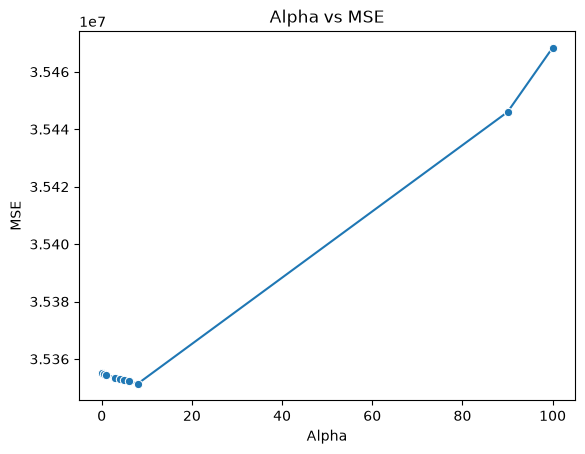

In [34]:
# # from the loop
# alpha = [00.1,0.003,0.004 , 0.4 , 1, 3,4,5,6,8,90,100]
# MSE = [] 
# for a in alpha:
#  model = linear_model.Lasso(alpha = a)
#  model.fit(X_train,y_train)
 
#  predict = model.predict(X_test)
#  mse =  mean_squared_error(y_test,predict)
#  MSE.append(mse)
#  print(f"for alpha values = {a} the mse value is :" , mse)
# sns.lineplot(x = a, y = MSE , marker ="o" )
alpha = [0.1, 0.003, 0.004, 0.4, 1, 3, 4, 5, 6, 8, 90, 100]
MSE = []

for a in alpha:
    model = linear_model.Lasso(alpha=a)
    model.fit(X_train, y_train)

    predict = model.predict(X_test)
    mse = mean_squared_error(y_test, predict)

    MSE.append(mse)

    print(f"For alpha = {a}, MSE = {mse}")

sns.lineplot(x=alpha, y=MSE, marker="o")
plt.xlabel("Alpha")
plt.ylabel("MSE")
plt.title("Alpha vs MSE")
plt.show()

In [36]:
from sklearn.linear_model import LassoCV

In [37]:
df = pd.read_csv("insurance.csv")

In [38]:
x = df.drop(columns = ["charges","region"]) 
y = df["charges"]
x["sex"] = x["sex"].map({"male" : 0 , "female" :  1})
x["smoker"] = x["smoker"].map({"yes" : 0 , "no" :  1}) 

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=42)

In [49]:
from sklearn.metrics import r2_score
model = LassoCV(
    alphas=100,
    max_iter=1000,
    random_state= 42,
    cv = 5 
)
model.fit(X_train,y_train)

print("best alpha: ", model.alpha_)

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("mse = ", mse)
print("s2 = ", r2)


best alpha:  53.07174983937598
mse =  35373938.4297386
s2 =  0.758613248571497
